# Audio pipeline & voiceprint verification 

This notebook covers the **sound** part of the multimodal authentication system:

1. Load each member's recordings ("Yes, approve" and "Confirm transaction")
2. Visualise them as waveforms and spectrograms
3. Apply augmentations (pitch shift, time stretch, background noise + gain/shift)
4. Extract features (MFCCs, spectral roll-off, RMS energy, ...) into `audio_features.csv`
5. Train and evaluate the **voiceprint verification model** (accuracy, F1, log loss)
6. Test unauthorised voices and the face-voice consistency check

All logic lives in `audio_pipeline.py` and `voice_model.py`, so the CLI app uses exactly the same code.

In [4]:
import sys, os

if "google.colab" in sys.modules:          # running on Colab
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Audio_features')
    !pip install -q librosa soundfile imageio-ffmpeg

sys.path.insert(0, os.getcwd())
print("Working in:", os.getcwd())

Working in: D:\Audio_features


In [5]:
import pandas as pd, matplotlib.pyplot as plt, json
from IPython.display import Audio, display
import audio_pipeline as ap
import voice_model as vm
%matplotlib inline

## 0. Convert the phone recordings
The members recorded on different phones (m4a / aac / mp4). `prepare_audio.py` converts each recording to 16 kHz mono WAV and names it `<member>_<phrase>_<take>.wav`.

In [6]:
!python prepare_audio.py

Emma Tiffany Umwari/confirm_transaction.m4a      -> data\audio\raw\emma_confirm_transaction_1.wav
Emma Tiffany Umwari/yes_approve.m4a              -> data\audio\raw\emma_yes_approve_1.wav
Hassan_Adelani_Luqman/approve.aac                  -> data\audio\raw\hassan_yes_approve_1.wav
Hassan_Adelani_Luqman/confirm_transaction.aac      -> data\audio\raw\hassan_confirm_transaction_1.wav
Parfait Shema Semana/approve.mp4                  -> data\audio\raw\parfait_yes_approve_1.wav
Parfait Shema Semana/confirm_transaction.mp4      -> data\audio\raw\parfait_confirm_transaction_1.wav
Peter Michael Angelo Rucakibungo/Approve.m4a                  -> data\audio\raw\peter_yes_approve_1.wav
Peter Michael Angelo Rucakibungo/Confirm transaction.m4a      -> data\audio\raw\peter_confirm_transaction_1.wav

Converted 8 recordings for 4 members.


## 1. Load recordings
Files are named `<member>_<phrase>_<take>.wav`. Each clip is converted to 16 kHz mono, leading and trailing silence is trimmed (30 dB), and the clip is peak-normalised so loud and quiet microphones are comparable.

In [7]:
dataset = ap.load_dataset()
dataset[["file", "member", "phrase", "take", "duration_s"]]

,file,member,phrase,take,duration_s
0,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,2.197312
1,emma_yes_approve_1.wav,emma,yes_approve,1,1.866688
2,hassan_confirm_transaction_1.wav,hassan,confirm_transaction,1,1.376000
3,hassan_yes_approve_1.wav,hassan,yes_approve,1,1.184000
4,parfait_confirm_transaction_1.wav,parfait,confirm_transaction,1,2.656000
5,parfait_yes_approve_1.wav,parfait,yes_approve,1,1.664000
6,peter_confirm_transaction_1.wav,peter,confirm_transaction,1,1.696000
7,peter_yes_approve_1.wav,peter,yes_approve,1,3.520000


In [8]:
dataset.groupby("member").agg(recordings=("file", "count"), phrases=("phrase", "nunique"),
                              mean_duration_s=("duration_s", "mean")).round(2)

,recordings,phrases,mean_duration_s
member,,,
emma,2,2,2.03
hassan,2,2,1.28
parfait,2,2,2.16
peter,2,2,2.61


In [9]:
# Listen to the first clip of each member
for _, r in dataset.groupby("member").head(1).iterrows():
    print(r.file); display(Audio(r.signal, rate=ap.SR))

emma_confirm_transaction_1.wav


hassan_confirm_transaction_1.wav


parfait_confirm_transaction_1.wav


peter_confirm_transaction_1.wav


## 2. Waveforms and spectrograms

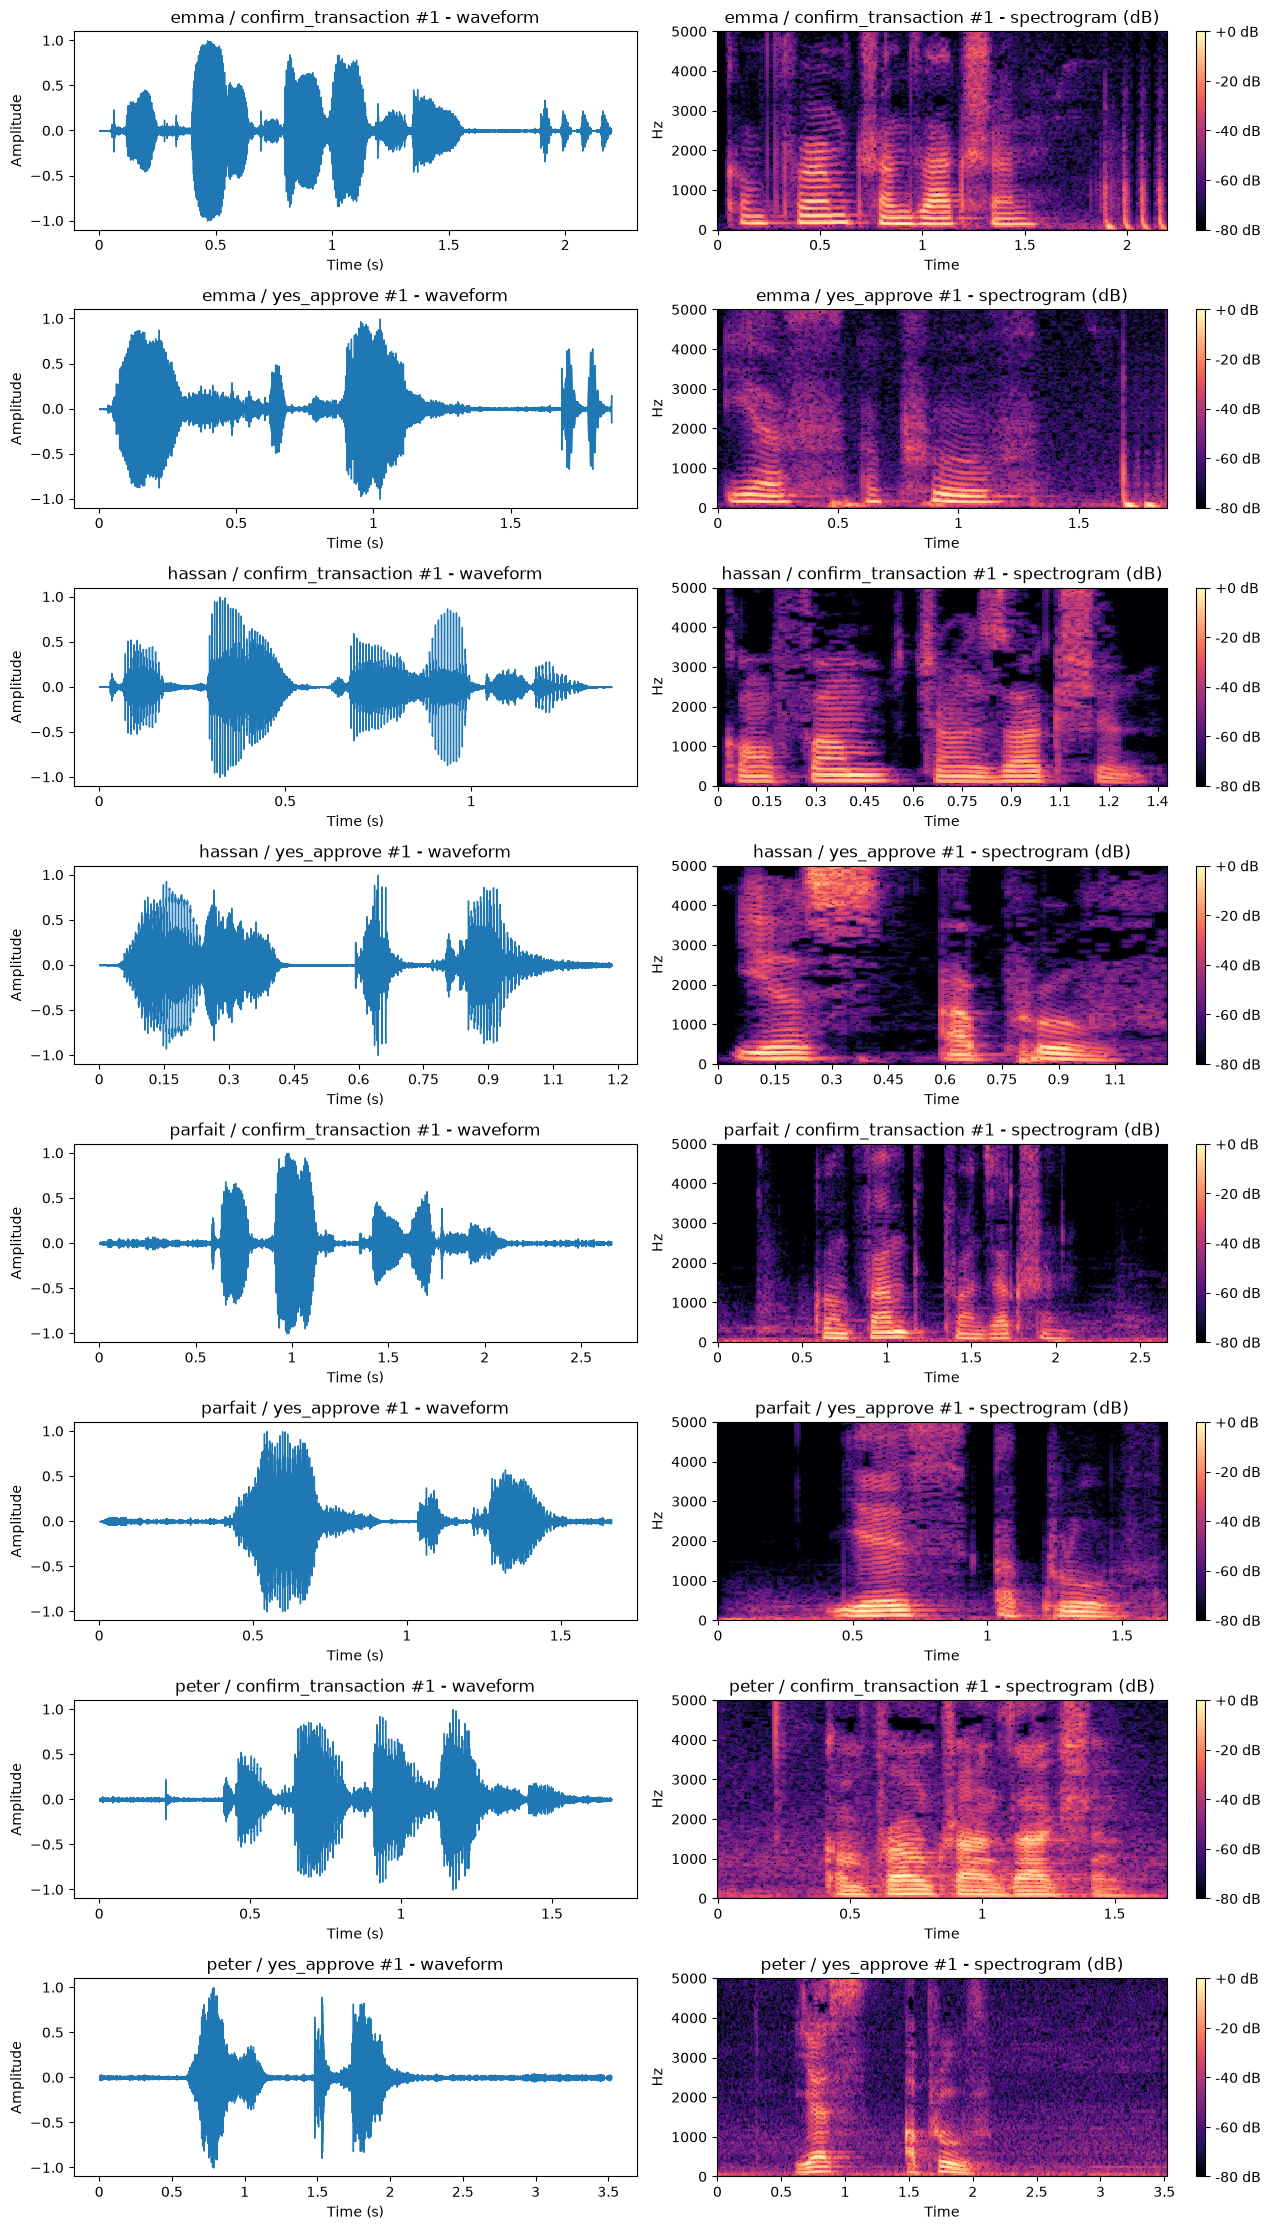

In [10]:
ap.FIG_DIR.mkdir(exist_ok=True)
ap.plot_all_members(dataset, ap.FIG_DIR / "audio_waveforms_spectrograms.png");

**Interpretation** *(edit this after looking at your own plots)*

- **Waveforms**: each phrase appears as bursts of energy, one per syllable. "Confirm transaction" has more bursts and lasts longer than "Yes, approve". Peaks near ±1 come from normalisation. Check that no clip is clipped flat at the top or bottom.
- **Spectrograms**: the horizontal stripes are **harmonics** of each speaker's pitch. Lower voices have stripes packed closer together. Where the energy sits (the bright bands, called formants) depends on each person's vocal tract. These differences are what the MFCC features capture.
- **Noise**: a quiet clip should show a dark background between words. A grey haze means background noise.

## 3. Augmentation
Each recording gets **5 augmented copies**: pitch +2 and -2 semitones, time stretch ×1.15 and ×0.85, and a noisy, quieter, delayed version (15 dB SNR, 0.6× gain, 100 ms shift). These simulate a speaker on a different day, at a different speed, or with a worse microphone.

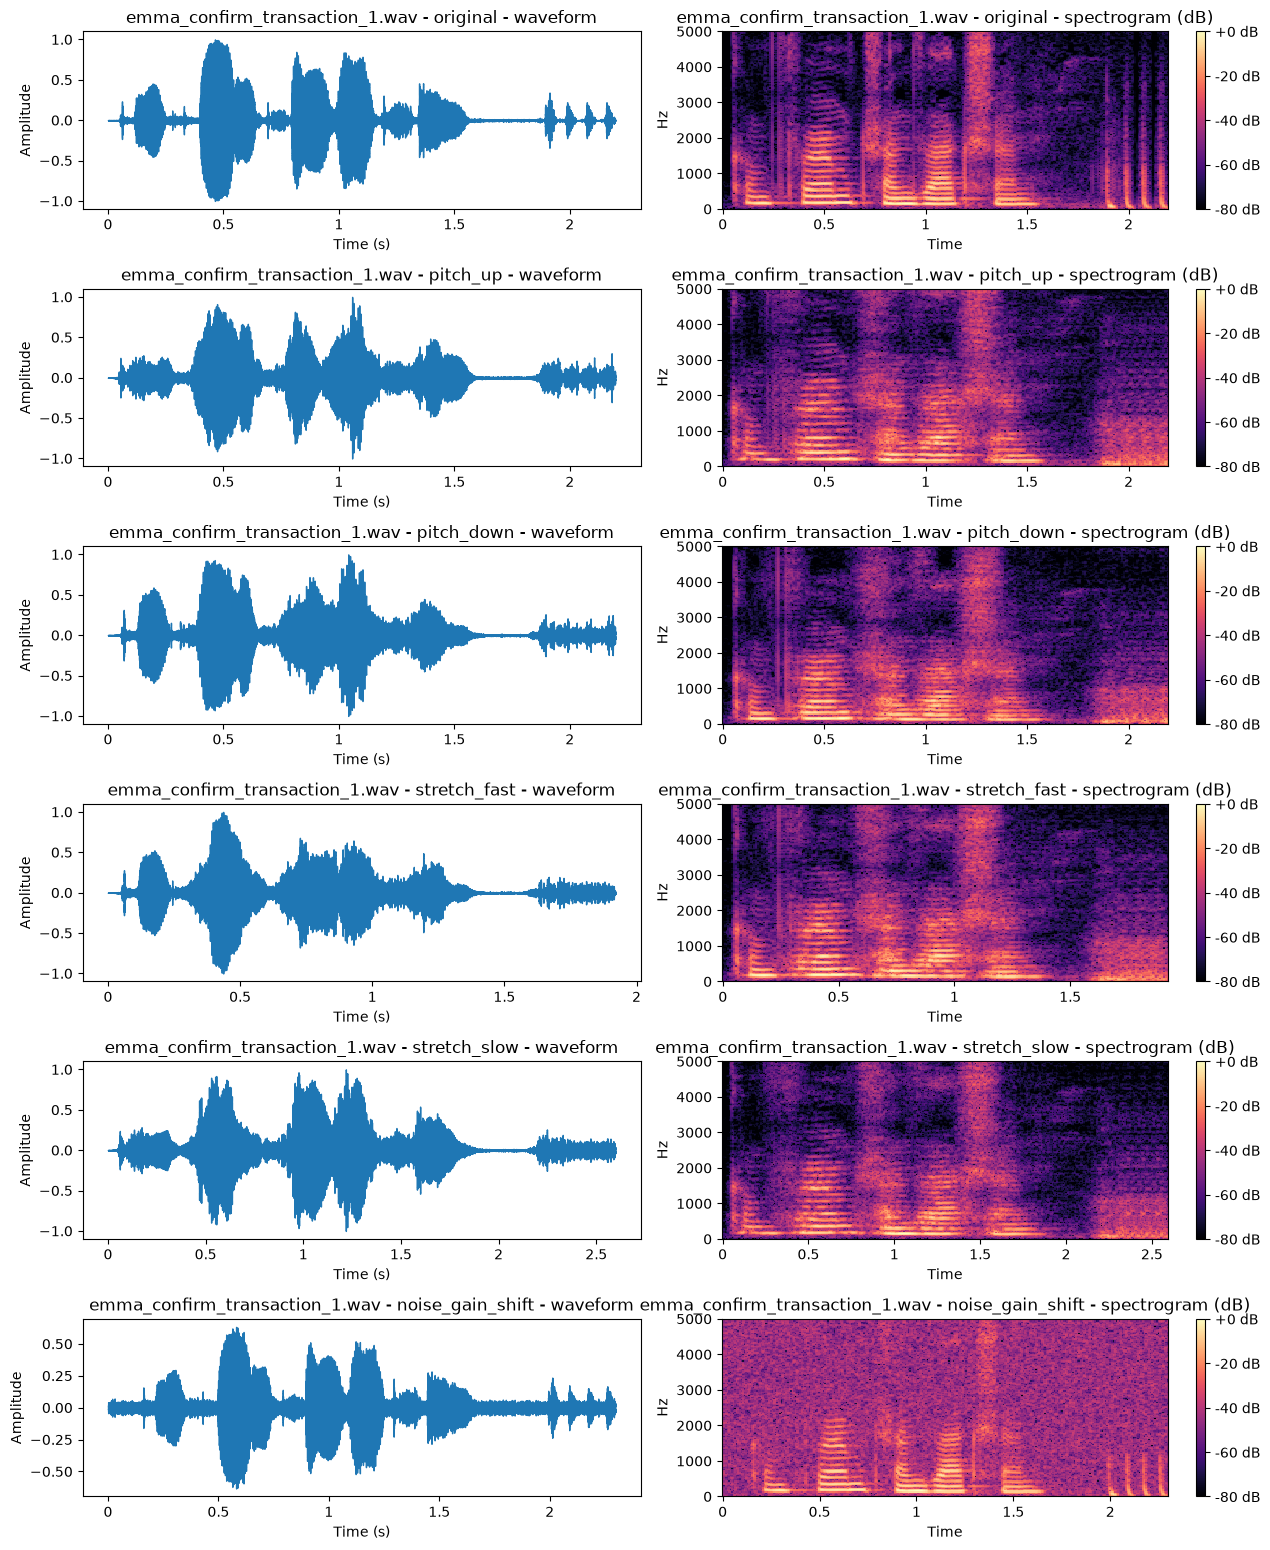

In [11]:
first = dataset.iloc[0]
ap.plot_augmentations(first.signal, first.file, ap.FIG_DIR / "audio_augmentations.png");

In [12]:
for name, sig in ap.augment(first.signal).items():
    print(name); display(Audio(sig, rate=ap.SR))

pitch_up


pitch_down


stretch_fast


stretch_slow


noise_gain_shift


## 4. Feature extraction → `audio_features.csv`

For every clip (original + augmented) the mean and standard deviation over time of these features are saved:

| Feature | Why it identifies a speaker |
|---|---|
| 13 MFCCs + 13 delta-MFCCs | shape of the vocal tract (timbre), and how it moves |
| Spectral roll-off (85%) | how much high-frequency energy the voice has |
| Spectral centroid / bandwidth | "brightness" and spread of the voice |
| Zero-crossing rate | noisiness and fricatives |
| RMS energy | loudness profile |
| Fundamental frequency (YIN) | the speaker's pitch |

Clip duration is left out on purpose: it describes the phrase, not the speaker.

In [13]:
features = ap.build_feature_table(dataset)
features.to_csv(ap.FEATURES_CSV, index=False)
print(features.shape, "->", ap.FEATURES_CSV.name)
features.head()

(48, 70) -> audio_features.csv


,file,member,phrase,take,augmentation,source_file,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,zcr_mean,zcr_std,rms_energy_mean,rms_energy_std,pitch_f0_mean,pitch_f0_std
0,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,original,emma_confirm_transaction_1.wav,-206.058670,89.070740,126.890976,53.360630,...,1274.041009,765.863933,1346.365996,464.948752,0.094366,0.076642,0.141014,0.104948,138.201274,44.909107
1,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,pitch_up,emma_confirm_transaction_1.wav,-186.800507,87.524872,118.061180,46.923027,...,1338.976862,712.789174,1451.410947,459.446445,0.094649,0.074428,0.137515,0.093724,153.229402,47.007232
2,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,pitch_down,emma_confirm_transaction_1.wav,-198.649902,87.552574,137.185196,45.046799,...,1097.289655,569.079854,1216.725659,386.730862,0.073674,0.060146,0.151263,0.113605,130.176754,42.904234
3,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,stretch_fast,emma_confirm_transaction_1.wav,-199.855774,89.446701,126.980782,45.333378,...,1227.029817,624.066052,1374.654067,410.290698,0.081583,0.063048,0.129369,0.090229,139.468856,45.029171
4,emma_confirm_transaction_1.wav,emma,confirm_transaction,1,stretch_slow,emma_confirm_transaction_1.wav,-196.788010,87.504898,124.773331,47.720181,...,1247.973717,676.235654,1373.125941,420.933295,0.087087,0.074034,0.138620,0.114143,135.836316,42.831838


In [14]:
cols = ap.feature_columns(features)
print(f"{len(cols)} features, nulls: {features[cols].isna().sum().sum()}")
features.groupby("augmentation").size()

64 features, nulls: 0


augmentation
noise_gain_shift    8
original            8
pitch_down          8
pitch_up            8
stretch_fast        8
stretch_slow        8
dtype: int64

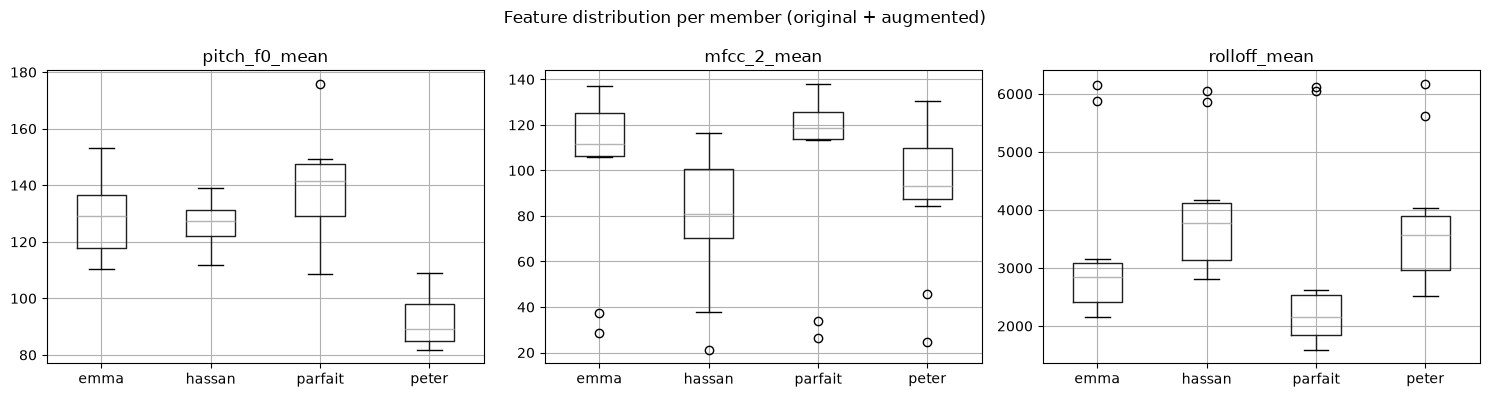

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["pitch_f0_mean", "mfcc_2_mean", "rolloff_mean"]):
    features.boxplot(column=col, by="member", ax=ax); ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Feature distribution per member (original + augmented)"); plt.tight_layout()
fig.savefig(ap.FIG_DIR / "audio_feature_boxplots.png", dpi=110)

**Interpretation**: when a member's boxes do not overlap with the others' (especially for pitch and the low MFCCs), the classifier can separate that voice easily. Wide boxes show the effect of augmentation: pitch shift spreads `pitch_f0_mean` on purpose, so the model cannot rely on pitch alone.

## 5. Voiceprint verification model

**Evaluation scheme: leave-one-recording-out.** Each fold holds out one original recording **and all its augmented copies**. Testing on augmented copies of training clips would leak information and overstate accuracy.

We compare **Logistic Regression** and **Random Forest** using accuracy, macro F1 and log loss, then keep the model with the lowest log loss.

**Rejecting unknown speakers.** A classifier always picks *some* member, so two extra checks are learned from held-out predictions:
- `prob_threshold`: minimum confidence, set at the 10th percentile of correct held-out predictions
- `dist_threshold`: maximum distance from the predicted member's average voiceprint, set at the 95th percentile of genuine held-out distances

In [16]:
summary = vm.train()

48 rows (8 original recordings), 64 features, members: emma, hassan, parfait, peter
  logistic_regression  {'accuracy': 0.4167, 'f1_macro': 0.4152, 'log_loss': 1.1355}
  random_forest        {'accuracy': 0.375, 'f1_macro': 0.3642, 'log_loss': 1.3047}
Best model: logistic_regression

              precision    recall  f1-score   support

        emma       0.38      0.42      0.40        12
      hassan       1.00      0.33      0.50        12
     parfait       0.40      0.67      0.50        12
       peter       0.27      0.25      0.26        12

    accuracy                           0.42        48
   macro avg       0.51      0.42      0.42        48
weighted avg       0.51      0.42      0.42        48

{
  "cv_scheme": "leave-one-recording-out (augmented copies held out with their source)",
  "best_model": "logistic_regression",
  "prob_threshold": 0.404,
  "dist_threshold": 2.444,
  "genuine_accept_rate_cv": 0.3542
}

Saved models\voice_model.joblib


In [17]:
pd.DataFrame(summary["models"]).T

,accuracy,f1_macro,log_loss
logistic_regression,0.4167,0.4152,1.1355
random_forest,0.3750,0.3642,1.3047


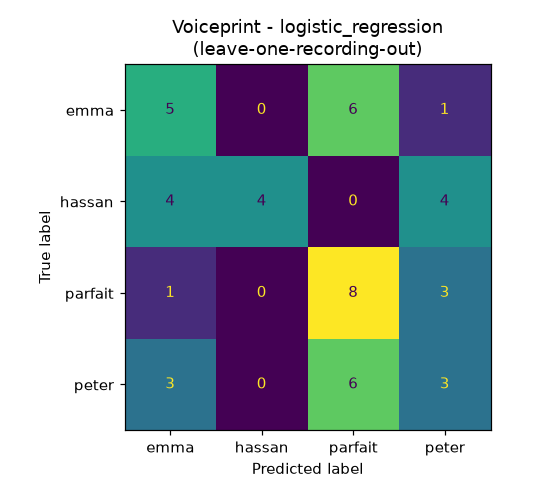

In [18]:
from IPython.display import Image
Image(str(ap.FIG_DIR / "voice_confusion_matrix.png"))

## 6. Authorisation tests
This uses the same `VoiceVerifier.verify()` call as the CLI app. `expected_member` is the person the **face model** recognised, so the voice must belong to the same person (multimodal check).

In [19]:
verifier = vm.VoiceVerifier.load()
member_clip = dataset.iloc[0]
print("Genuine, matching face :", verifier.verify(member_clip.path, expected_member=member_clip.member)["reason"])
other = sorted(set(dataset.member) - {member_clip.member})[0]
print("Genuine, mismatched face:", verifier.verify(member_clip.path, expected_member=other)["reason"])

Genuine, matching face : voice verified
Genuine, mismatched face: voice belongs to 'emma', but face was 'hassan'


In [20]:
unauth = ap.list_audio(ap.UNAUTH_DIR) if ap.UNAUTH_DIR.exists() else []
rows = [{"file": p.name, **{k: v for k, v in verifier.verify(p).items() if k != "probabilities"}} for p in unauth]
pd.DataFrame(rows) if rows else print("Add non-member recordings to data/audio/unauthorized/")

Add non-member recordings to data/audio/unauthorized/


## 7. Summary *(fill in with your numbers)*

- Recordings: _N_ originals × 6 versions = _M_ rows in `audio_features.csv`, 64 features each
- Best model: _..._, accuracy _..._, macro F1 _..._, log loss _..._ (leave-one-recording-out)
- Genuine accept rate with thresholds: _..._ ; unauthorised reject rate: _..._
- Limitations: few recordings per person and one recording environment. More takes per member would make the thresholds more reliable.